In [1]:
from dataclasses import dataclass

import ipywidgets
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize
import scipy.stats
import xarray

plt.rc("figure", figsize=(6, 2))


def to_direction(x: xarray.DataArray, axis):
    norm = (x**2).sum(axis) ** 0.5
    return x / norm


@dataclass
class NNMF:
    eps: float = 0
    do_w: bool = True
    do_h: bool = True

    def step(self, W, H, X):
        if self.do_w:
            hht = H @ H.T
            xht = X @ H.T
            W = W * (xht / (W @ hht + self.eps))

        if self.do_h:
            wtw = W.T @ W
            wtx = W.T @ X
            H = H * (wtx / (wtw @ H + self.eps))

        # normalize
        scale = H.sum(1, keepdims=True)
        W *= scale[:, 0]
        H /= scale

        return W, H

    def loop(self, W, H, X, *, iterations: int, intermediate_steps: bool = False):
        if intermediate_steps:
            Ws = []
            Hs = []

        for _ in range(iterations):
            W, H = self.step(W, H, X)
            if intermediate_steps:
                Ws.append(W)
                Hs.append(H)

        if intermediate_steps:
            return Ws, Hs
        else:
            return W, H

## Define components

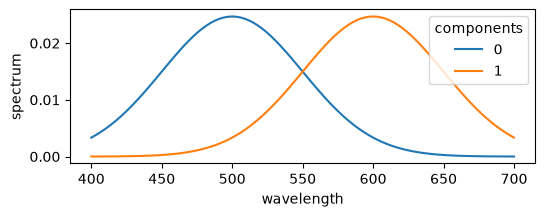

In [2]:
def generate_components_from_dist(component_pdfs: list) -> xarray.DataArray:
    """Generate a DataArray of (components, wavelength)."""

    # Fixed wavelength range
    wavelength = xarray.DataArray(np.linspace(400, 700, 100), dims=["wavelength"])

    components = np.zeros((len(component_pdfs), wavelength.size))
    for i, c in enumerate(component_pdfs):
        components[i] = c.pdf(wavelength)
        # It's missing the wavelength step to be the integral over the range
        components[i] /= components[i].sum()

    return xarray.DataArray(
        components,
        dims=["components", "wavelength"],
        coords={"wavelength": wavelength},
        name="spectrum",
    )


components_wavelength = generate_components_from_dist(
    [
        scipy.stats.norm(500, 50),
        scipy.stats.norm(600, 50),
    ]
)

components_wavelength.plot(hue="components")

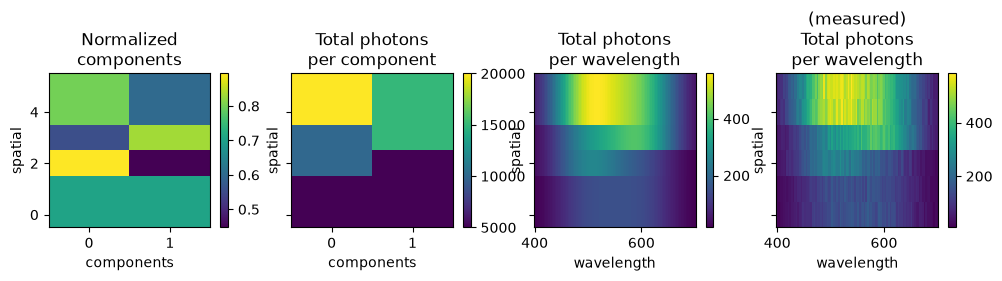

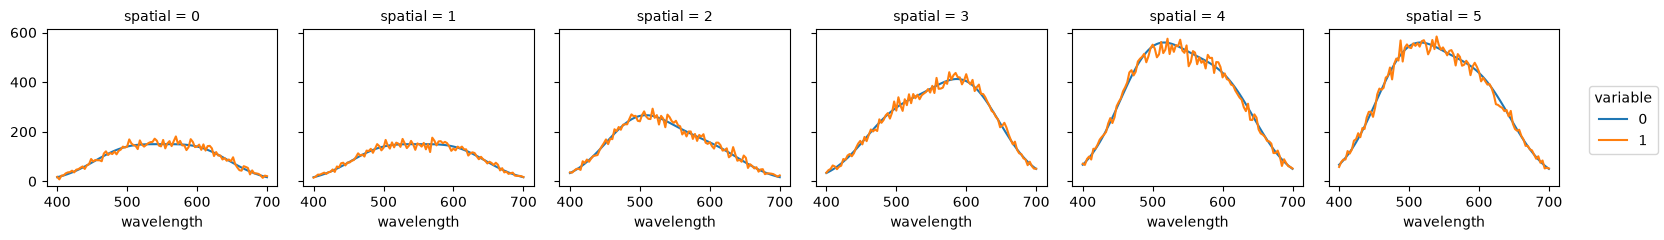

In [3]:
photons_component = 5000 * xarray.DataArray(
    np.array([[1, 1], [1, 1], [2, 1], [2, 3], [4, 3], [4, 3]]),
    dims=["spatial", "components"],
)
photons_wavelength = photons_component @ components_wavelength

rng = np.random.default_rng(0)
photons_wavelength_measured = xarray.apply_ufunc(rng.poisson, photons_wavelength)

fig, axes = plt.subplots(ncols=4, sharey=True, figsize=(12, 2))

to_direction(photons_component, "components").plot(ax=axes[0])
axes[0].set(title="Normalized\ncomponents")

photons_component.plot(ax=axes[1])
axes[1].set(title="Total photons\nper component")

photons_wavelength.plot.imshow(ax=axes[2], interpolation="none")
axes[2].set(title="Total photons\nper wavelength")

photons_wavelength_measured.plot.imshow(ax=axes[3], interpolation="none")
axes[3].set(title="(measured)\nTotal photons\nper wavelength")

xarray.concat(
    (photons_wavelength, photons_wavelength_measured),
    "variable",
).plot(hue="variable", col="spatial", size=2.5)

In [8]:
@ipywidgets.interact(seed=(0, 50))
def _(seed):
    rng = np.random.default_rng(seed)
    uniform = lambda x: rng.uniform(0, 1, x.shape)
    photons_components_est = xarray.apply_ufunc(uniform, photons_component).data
    # components_wavelength_est = xarray.apply_ufunc(uniform, components_wavelength).data
    components_wavelength_est = components_wavelength.data
    photons_wavelength_measured = xarray.apply_ufunc(
        rng.poisson, photons_wavelength
    ).data

    photons_components_est, components_wavelength_est = NNMF(eps=1e-10).loop(
        W=photons_components_est,
        H=components_wavelength_est,
        X=photons_wavelength_measured,
        iterations=200,
        intermediate_steps=True,
    )
    photons_components_est = xarray.DataArray(
        photons_components_est, dims=["iterations", *photons_component.dims]
    )
    components_wavelength_est = xarray.DataArray(
        components_wavelength_est, dims=["iterations", *components_wavelength.dims]
    )

    photons_components_est.plot(x="iterations", hue="spatial", col="components")

    # ((photons_components_est - photons_component) / photons_component).plot(
    #     x="iterations", hue="spatial", col="components"
    # )
    plt.show()

interactive(children=(IntSlider(value=25, description='seed', max=50), Output()), _dom_classes=('widget-intera…

In [ ]:
(
    xarray.Dataset(
        {
            "real": components_wavelength,
            "reconstructed": components_wavelength_est,
        }
    )
    .sel(iterations=-1)
    .to_dataarray()
    .plot(hue="variable", x="wavelength", col="components")
)

In [ ]:
(
    components_wavelength_est.sel(iterations=slice(None, None, 100)).plot(
        x="wavelength",
        hue="iterations",
        col="components",
    )
)